# Notebook 15 — Mini Assessment

## Section A: Conceptual Questions

1. What is Exploratory Data Analysis (EDA)?
2. Why is EDA performed before Machine Learning?
3. What is the difference between univariate, bivariate, and multivariate analysis?
4. How do you identify missing values in a dataset?
5. How do you identify duplicate records?
6. What is an outlier?
7. Explain the IQR method for detecting outliers.
8. What is skewness?
9. What is correlation?
10. What is the difference between correlation and causation?
11. What is multicollinearity?
12. How do you identify class imbalance?
13. Why should outliers not always be removed?

## Section B: Coding Exercises

14. Load a dataset into a Pandas DataFrame and display its first five rows.
15. Create a correlation heatmap for numerical columns.
16. Detect outliers using the IQR method.
17. Analyze the distribution of a numerical feature using a histogram.
18. Perform categorical analysis by displaying category counts and percentages.
19. Generate a complete EDA summary containing dataset shape, data types, missing values, duplicates, descriptive statistics, and numerical correlations.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the Titanic dataset
df = sns.load_dataset("titanic")

# Display the first five rows
display(df.head())

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## Section A: Conceptual Answers

### 1. What is EDA?
Exploratory Data Analysis (EDA) is the process of examining and visualizing data to understand its structure, patterns, and relationships.

### 2. Why is EDA performed before Machine Learning?
EDA helps identify missing values, duplicates, outliers, and important patterns before training a machine learning model.

### 3. Difference between univariate, bivariate, and multivariate analysis
- **Univariate:** Analyzes one variable.
- **Bivariate:** Analyzes two variables.
- **Multivariate:** Analyzes three or more variables together.

### 4. How do you identify missing values?
Use `df.isnull().sum()` to count missing values in each column.

### 5. How do you identify duplicate records?
Use `df.duplicated().sum()` to count duplicate rows.

### 6. What is an outlier?
An outlier is a data point that differs significantly from most other observations.

### 7. Explain the IQR method.
IQR is calculated as Q3 − Q1. Values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR are potential outliers.

### 8. What is skewness?
Skewness measures the asymmetry of a data distribution. It can be positive, negative, or approximately zero.

### 9. What is correlation?
Correlation measures the strength and direction of the relationship between two variables.

### 10. Difference between correlation and causation
Correlation means two variables are related; causation means one variable directly influences another.

### 11. What is multicollinearity?
Multicollinearity occurs when two or more independent variables in a model are strongly related to each other.

### 12. How do you identify class imbalance?
Use `df["target"].value_counts()` to compare the number of observations in each target class.

### 13. Why should outliers not always be removed?
Some outliers represent valid and important observations. Removing them without investigation can lose useful information.

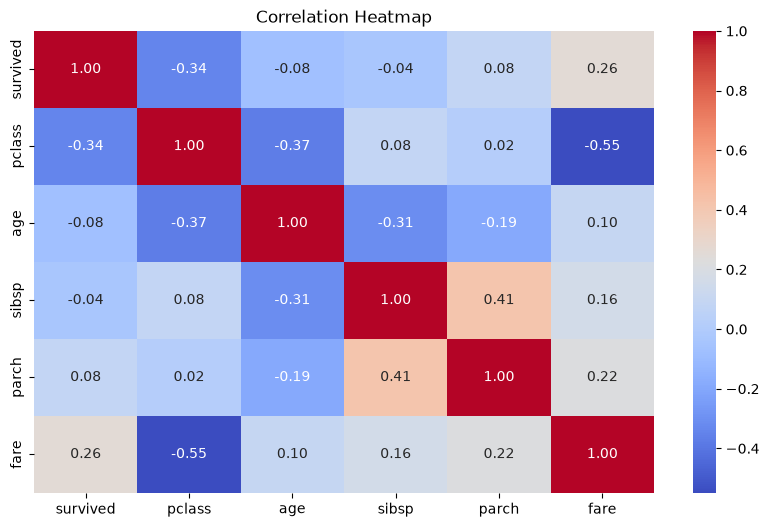

In [2]:
# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlations
correlation_matrix = numeric_df.corr()

# Plot correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [3]:
# Select numerical columns
numeric_cols = df.select_dtypes(include="number").columns

# Detect outliers using IQR
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(f"\nColumn: {col}")
    print("Lower limit:", round(lower_limit, 2))
    print("Upper limit:", round(upper_limit, 2))
    print("Number of outliers:", len(outliers))


Column: survived
Lower limit: -1.5
Upper limit: 2.5
Number of outliers: 0

Column: pclass
Lower limit: 0.5
Upper limit: 4.5
Number of outliers: 0

Column: age
Lower limit: -6.69
Upper limit: 64.81
Number of outliers: 11

Column: sibsp
Lower limit: -1.5
Upper limit: 2.5
Number of outliers: 46

Column: parch
Lower limit: 0.0
Upper limit: 0.0
Number of outliers: 213

Column: fare
Lower limit: -26.72
Upper limit: 65.63
Number of outliers: 116


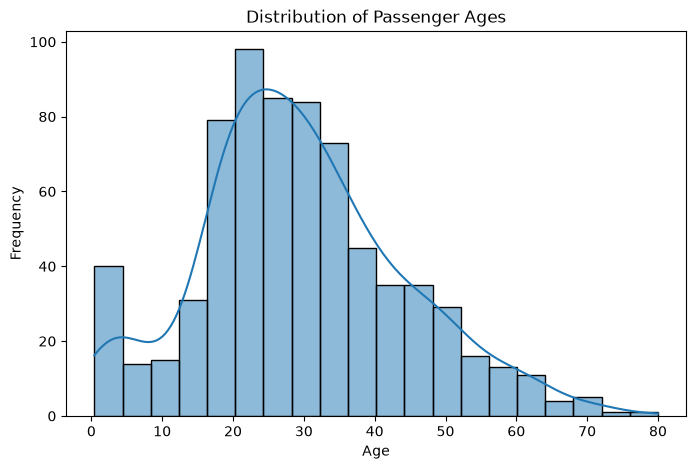

Age mean: 29.69911764705882
Age median: 28.0
Age skewness: 0.38910778230082704


In [4]:
# Analyze the age distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    bins=20,
    kde=True
)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

# Calculate distribution statistics
print("Age mean:", df["age"].mean())
print("Age median:", df["age"].median())
print("Age skewness:", df["age"].skew())


Column: sex

Category counts:


sex
male      577
female    314
Name: count, dtype: int64


Category percentages:


sex
male      64.76
female    35.24
Name: proportion, dtype: float64


Column: embarked

Category counts:


...

alive
no     61.62
yes    38.38
Name: proportion, dtype: float64


Column: alone

Category counts:


alone
True     537
False    354
Name: count, dtype: int64


Category percentages:


alone
True     60.27
False    39.73
Name: proportion, dtype: float64

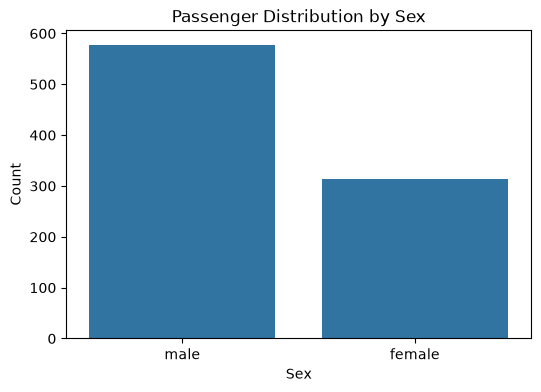

In [5]:
# Select categorical columns
categorical_cols = df.select_dtypes(
    include=["object", "str", "category", "bool"]
).columns

# Display counts and percentages for each categorical column
for col in categorical_cols:
    print(f"\nColumn: {col}")

    print("\nCategory counts:")
    display(df[col].value_counts(dropna=False))

    print("\nCategory percentages:")
    display(
        (df[col].value_counts(normalize=True, dropna=False) * 100)
        .round(2)
    )

# Visualize the passenger sex distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="sex")
plt.title("Passenger Distribution by Sex")
plt.xlabel("Sex")
plt.ylabel("Count")
plt.show()

In [6]:
# 1. Dataset overview
print("DATASET OVERVIEW")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nCOLUMN DATA TYPES")
display(df.dtypes.to_frame("Data Type"))

# 2. Missing values
print("\nMISSING VALUES")
display(
    df.isnull().sum()
    .to_frame("Missing Count")
    .query("`Missing Count` > 0")
)

# 3. Duplicate rows
print("\nDUPLICATE ROWS:", df.duplicated().sum())

# 4. Numerical descriptive statistics
print("\nNUMERICAL SUMMARY")
display(df.describe())

# 5. Categorical summary
print("\nCATEGORICAL SUMMARY")
display(
    df.describe(include=["object", "str", "category", "bool"])
)

# 6. Numerical correlations
print("\nNUMERICAL CORRELATIONS")
display(df.select_dtypes(include="number").corr().round(2))

DATASET OVERVIEW
Rows: 891
Columns: 15

COLUMN DATA TYPES


,Data Type
survived,int64
pclass,int64
sex,str
age,float64
sibsp,int64
parch,int64
fare,float64
embarked,str
class,category
who,str



MISSING VALUES


,Missing Count
age,177
embarked,2
deck,688
embark_town,2



DUPLICATE ROWS: 107

NUMERICAL SUMMARY


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



CATEGORICAL SUMMARY


,sex,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891,889,891,891,891,203,889,891,891
unique,2,3,3,3,2,7,3,2,2
top,male,S,Third,man,True,C,Southampton,no,True
freq,577,644,491,537,537,59,644,549,537



NUMERICAL CORRELATIONS


,survived,pclass,age,sibsp,parch,fare
survived,1.00,-0.34,-0.08,-0.04,0.08,0.26
pclass,-0.34,1.00,-0.37,0.08,0.02,-0.55
age,-0.08,-0.37,1.00,-0.31,-0.19,0.10
sibsp,-0.04,0.08,-0.31,1.00,0.41,0.16
parch,0.08,0.02,-0.19,0.41,1.00,0.22
fare,0.26,-0.55,0.10,0.16,0.22,1.00
